# KuaiRand data exploration

## Loading data

In [21]:
from pathlib import Path

folder = Path("KuaiRand-1K")
archive = Path("KuaiRand-1K.tar.gz")

if folder.exists():
    print("KuaiRand-1K already extracted, skipping extraction.")
else:
    if not archive.exists():
        print("Archive not found, downloading it...")
        !wget https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz
    else:
        print("Archive already present, skipping download.")
    !tar -xzvf KuaiRand-1K.tar.gz

KuaiRand-1K already extracted, skipping extraction.


In [22]:
from pathlib import Path
import tarfile
import urllib.request
import sys

ROOT = Path(".")
DATA_DIR = Path.joinpath(ROOT,"KuaiRand-1K","data") 
URL = "https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz"

if not DATA_DIR.exists():
    archive = ROOT / "KuaiRand-1K.tar.gz"
    if not archive.exists():
        print("Downloading the archive (~1.1 GB)...")
        urllib.request.urlretrieve(URL, archive)
    print("Extracting...")
    with tarfile.open(archive, "r:gz") as tf:
        tf.extractall(ROOT, filter="data")

for f in sorted(DATA_DIR.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:8.0f} MB")

log_random_4_22_to_5_08_1k.csv                  3 MB
log_standard_4_08_to_4_21_1k.csv              374 MB
log_standard_4_22_to_5_08_1k.csv              492 MB
user_features_1k.csv                            0 MB
video_features_basic_1k.csv                   377 MB
video_features_statistic_1k.csv              3371 MB


In [23]:
import pandas as pd
from matplotlib import pyplot as plt

In [24]:
import numpy as np
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LogNorm

## Data exploration on the datasets
### Log standard dataset
The standard log is split into two files: 2022-04-08 → 04-21 and 2022-04-22 → 05-08. We load both into a single dataframe; the first window will be the training period and the second the test period.

One row is one video shown to the user.

All the analyses in this section are on the **raw data**: duplicates and zero-duration rows are kept on purpose, because they may be explained by the video features.

In [25]:
PATH_LOG_1 = DATA_DIR / "log_standard_4_08_to_4_21_1k.csv"
PATH_LOG_2 = DATA_DIR / "log_standard_4_22_to_5_08_1k.csv"

columns = pd.read_csv(PATH_LOG_1, nrows=0).columns            # header only, no rows
FLAGS = [c for c in columns if c.startswith("is") or c == "long_view"]
TIME_COLS = ["play_time_ms", "duration_ms", "profile_stay_time", "comment_stay_time"]

# read_csv has no automatic downcast: narrow types where the range is known by definition,
# read the durations as int64 and let to_numeric pick the smallest type that holds all values
LOG_DTYPES = {
    "user_id": "int16", "video_id": "int32", "date": "int32", "hourmin": "int16",
    "time_ms": "int64", "tab": "int8",
    **{c: "int8" for c in FLAGS},
    **{c: "int64" for c in TIME_COLS},
}

def load_log(path):
    df = pd.read_csv(path, dtype=LOG_DTYPES)
    for c in TIME_COLS:
        df[c] = pd.to_numeric(df[c], downcast="integer")
    return df

df_log = pd.concat([load_log(PATH_LOG_1), load_log(PATH_LOG_2)], ignore_index=True)
print(f"Rows: {len(df_log):,}   Memory: {df_log.memory_usage(deep=True).sum() / 2**20:.0f} MiB")

Rows: 11,713,045   Memory: 514 MiB


In [26]:
df_log.info(memory_usage="deep", show_counts=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11713045 entries, 0 to 11713044
Data columns (total 19 columns):
 #   Column             Non-Null Count     Dtype
---  ------             --------------     -----
 0   user_id            11713045 non-null  int16
 1   video_id           11713045 non-null  int32
 2   date               11713045 non-null  int32
 3   hourmin            11713045 non-null  int16
 4   time_ms            11713045 non-null  int64
 5   is_click           11713045 non-null  int8 
 6   is_like            11713045 non-null  int8 
 7   is_follow          11713045 non-null  int8 
 8   is_comment         11713045 non-null  int8 
 9   is_forward         11713045 non-null  int8 
 10  is_hate            11713045 non-null  int8 
 11  long_view          11713045 non-null  int8 
 12  play_time_ms       11713045 non-null  int32
 13  duration_ms        11713045 non-null  int32
 14  profile_stay_time  11713045 non-null  int32
 15  comment_stay_time  11713045 non-null  int32
 16

In [27]:
pd.set_option("display.float_format", "{:,.2f}".format)
df_log.describe()

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
count,"11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00"
mean,509.24,"2,182,057.10","20,220,443.09","1,427.37","1,650,727,874,486.51",0.38,0.02,0.00,0.00,0.00,0.00,0.26,"14,790.27","72,180.92",6.82,491.49,0.02,0.00,1.19
std,296.17,"1,264,812.81",38.85,618.44,"782,359,745.50",0.48,0.12,0.03,0.05,0.03,0.03,0.44,"34,366.20","103,042.99","1,055.20","3,964.02",0.13,0.00,1.30
min,0.00,1.00,"20,220,408.00",0.00,"1,649,340,003,236.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,238.00,"1,088,361.00","20,220,416.00","1,000.00","1,650,042,171,534.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,011.00","10,366.00",0.00,0.00,0.00,0.00,1.00
50%,519.00,"2,183,648.00","20,220,424.00","1,500.00","1,650,732,742,443.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,"3,023.00","29,066.00",0.00,0.00,0.00,0.00,1.00
75%,781.00,"3,276,703.00","20,220,501.00","2,000.00","1,651,410,076,622.00",1.00,0.00,0.00,0.00,0.00,0.00,1.00,"12,631.00","95,633.00",0.00,0.00,0.00,0.00,1.00
max,999.00,"4,371,899.00","20,220,508.00","2,300.00","1,652,025,129,022.00",1.00,1.00,1.00,1.00,1.00,1.00,1.00,"1,529,347.00","16,513,080.00","300,000.00","300,000.00",1.00,0.00,14.00


In [28]:
print("Unique values")
display(df_log.nunique())
print("Total values: ", len(df_log))

n_dup = df_log.duplicated(["user_id", "video_id", "time_ms"]).sum()
print(f"Duplicate rows (user, video, instant): {n_dup}")
print(f"Videos with duration 0:   {(df_log['duration_ms'] == 0).sum()}")
print(f"play_time > duration:   {(df_log['play_time_ms'] > df_log['duration_ms']).mean():.1%} of the rows")

Unique values


user_id                 1000
video_id             4369953
date                      31
hourmin                   24
time_ms              2029765
is_click                   2
is_like                    2
is_follow                  2
is_comment                 2
is_forward                 2
is_hate                    2
long_view                  2
play_time_ms          248029
duration_ms           212171
profile_stay_time       2020
comment_stay_time      52100
is_profile_enter           2
is_rand                    1
tab                       15
dtype: int64

Total values:  11713045
Duplicate rows (user, video, instant): 101220
Videos with duration 0:   937643
play_time > duration:   20.8% of the rows


#### What do the tabs represent?


Each tab represents the way a video is recommended to the user (e.g. feed, recommendations screen, etc...)

There is no description of the mapping between a tab and a type of scenario, so it has to be inferred from the data. However, it would be interesting to isolate and study the interactions among videos of the same tab only.

In [29]:
pd.DataFrame({"value counts": df_log['tab'].value_counts(),
              "percentage of total" :df_log['tab'].value_counts()/len(df_log)*100})

,value counts,percentage of total
tab,,
1,7717601,65.89
0,2407352,20.55
4,895385,7.64
2,402293,3.43
6,183403,1.57
3,37418,0.32
11,17574,0.15
8,17430,0.15
5,16424,0.14


Tabs 1, 0 and 4 alone cover about 93% of the rows. Volume alone, however, is not enough to decide which tabs to study: the cells below check whether the tabs behave alike, and tab 0 turns out to behave very differently from tabs 1 and 4.

In [30]:
block_size = df_log.groupby(["user_id", "time_ms"])["video_id"].transform("size")

tab_profile = (df_log.assign(never_opened=df_log["play_time_ms"].eq(0), block=block_size)
               .groupby("tab")
               .agg(rows=("user_id", "size"),
                    users=("user_id", "nunique"),
                    median_block=("block", "median"),
                    never_opened=("never_opened", "mean"),
                    is_click=("is_click", "mean"),
                    long_view=("long_view", "mean"),
                    like=("is_like", "mean")))
tab_profile.insert(1, "share_of_rows", tab_profile["rows"] / tab_profile["rows"].sum())
tab_profile.style.format({"rows": "{:,}", "users": "{:,}", "median_block": "{:.0f}",
                          **{c: "{:.1%}" for c in ["share_of_rows", "never_opened", "is_click", "long_view", "like"]}})

,rows,share_of_rows,users,median_block,never_opened,is_click,long_view,like
tab,,,,,,,,
0,"2,407,352",20.6%,961,11,88.5%,12.0%,4.0%,0.4%
1,"7,717,601",65.9%,991,6,1.2%,44.5%,31.7%,1.9%
2,"402,293",3.4%,171,6,1.0%,39.1%,30.9%,1.3%
3,"37,418",0.3%,663,11,97.6%,2.5%,0.4%,0.1%
4,"895,385",7.6%,832,6,3.8%,56.0%,42.8%,1.9%
5,"16,424",0.1%,103,8,0.1%,21.3%,11.2%,0.4%
6,"183,403",1.6%,832,8,0.1%,18.1%,8.7%,0.7%
7,"3,833",0.0%,61,5,44.7%,51.0%,31.0%,3.9%
8,"17,430",0.1%,154,8,96.9%,3.6%,1.8%,0.1%


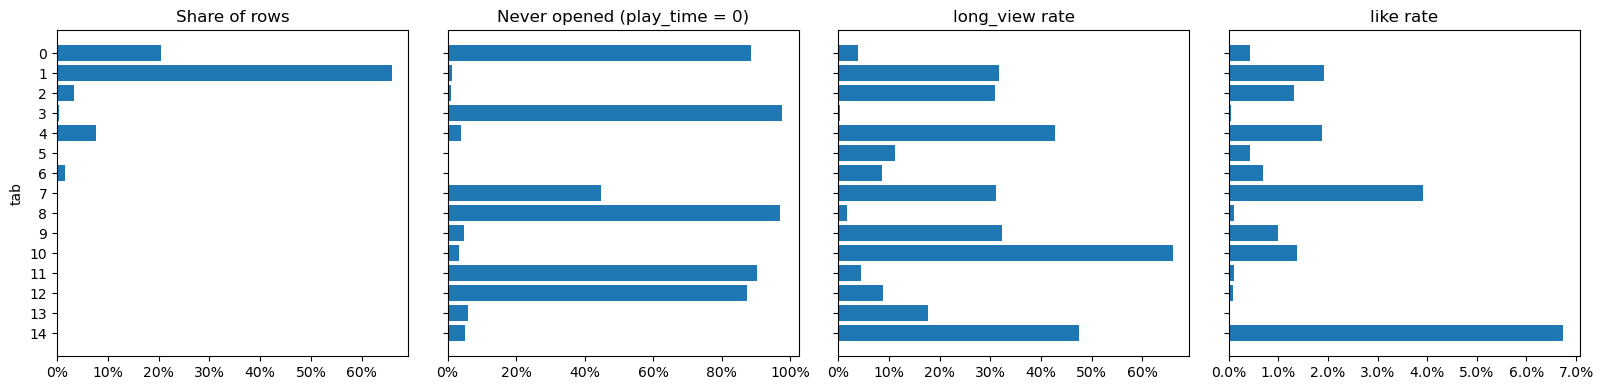

In [31]:
tab_stats = (df_log.assign(never_opened=df_log["play_time_ms"].eq(0))
             .groupby("tab")
             .agg(rows=("user_id", "size"),
                  never_opened=("never_opened", "mean"),
                  long_view=("long_view", "mean"),
                  like=("is_like", "mean")))
tab_stats["share_of_rows"] = tab_stats["rows"] / tab_stats["rows"].sum()

cols = ["share_of_rows", "never_opened", "long_view", "like"]
titles = ["Share of rows", "Never opened (play_time = 0)", "long_view rate", "like rate"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col, title in zip(axes, cols, titles):
    ax.barh(tab_stats.index.astype(str), tab_stats[col])
    ax.set_title(title)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("tab")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

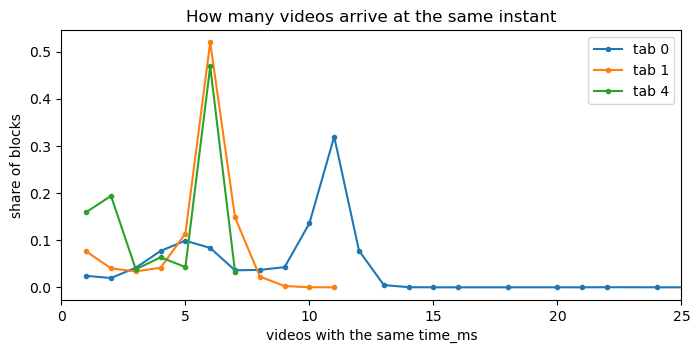

Rows sharing their time_ms with other videos: 98.7%


In [32]:
batch = df_log.groupby(["tab", "user_id", "time_ms"]).size()

fig, ax = plt.subplots(figsize=(8, 3.5))
for t in [0, 1, 4]:
    dist = batch.loc[t].value_counts(normalize=True).sort_index()
    ax.plot(dist.index, dist.values, marker="o", ms=3, label=f"tab {t}")
ax.set(xlim=(0, 25), xlabel="videos with the same time_ms", ylabel="share of blocks",
       title="How many videos arrive at the same instant")
ax.legend()
plt.show()

shared = df_log.groupby(["user_id", "time_ms"])["video_id"].transform("size") > 1
print(f"Rows sharing their time_ms with other videos: {shared.mean():.1%}")

What I mean by "request" and "6 videos"

A short-video app does not download one video at a time. When you are about to finish the ones already loaded, the app asks the server for a new block of videos and the server sends them all together. In the log, all the videos of that block have the same time_ms: it is the instant at which the block arrived, not the one at which you watched each video.

To measure how many videos arrive in each block, the plot groups the rows by (user_id, time_ms) and counts how many rows each group has. This is what df_log.groupby(["tab", "user_id", "time_ms"]).size() does. Then it looks at which sizes are the most frequent:

Tab 1 and 4: the peak is at 6, i.e. about half of the blocks contain exactly 6 videos. This makes sense for a full-screen feed: the app loads the next 6 videos to scroll through one at a time.
Tab 0: the peak is between 10 and 12. This makes sense for a grid: a two-column screen shows many thumbnails together, so a larger block is needed to fill it.

In [33]:
t0 = df_log[df_log["tab"] == 0]
pd.crosstab(t0["is_click"], t0["play_time_ms"] > 0,
            rownames=["is_click"], colnames=["played (play_time > 0)"], normalize="all")

played (play_time > 0),False,True
is_click,,
0,0.88,0.00
1,0.01,0.11


In [34]:
# One row per block (same user, same time_ms), in time order
blocks = (df_log.drop_duplicates(["user_id", "time_ms"])[["user_id", "time_ms", "tab"]]
                .sort_values(["user_id", "time_ms"]))
blocks["prev_tab"] = blocks.groupby("user_id")["tab"].shift()
blocks["prev_time"] = blocks.groupby("user_id")["time_ms"].shift()
blocks["gap_s"] = (blocks["time_ms"] - blocks["prev_time"]) / 1000

# An "entry" into a tab is a block whose previous block was in a different tab
entries = blocks[blocks["tab"].isin([1, 2, 4]) & blocks["prev_tab"].notna() & (blocks["prev_tab"] != blocks["tab"])]
SHOWN = [0, 1, 2, 3, 4, 5, 6]     # the tabs with >0.1% of the rows; the rest are grouped as "other"
prev = entries["prev_tab"].astype(int).astype(str).where(entries["prev_tab"].isin(SHOWN), "other")
entry_table = pd.crosstab(entries["tab"], prev, normalize="index")
entry_table["entries"] = entries.groupby("tab").size()
entry_table["median_gap_s"] = entries.groupby("tab")["gap_s"].median()
display(entry_table.style.format({c: "{:.1%}" for c in entry_table.columns[:-2]} | {"entries": "{:,}", "median_gap_s": "{:.0f}"}))

# Once inside a tab, do users stay there? Share of blocks whose previous block is in the same tab
same_tab = (blocks["prev_tab"] == blocks["tab"]).groupby(blocks["tab"]).mean()
print("Blocks preceded by a block of the same tab:", same_tab.loc[[0, 1, 2, 4]].map("{:.1%}".format).to_dict())

# Tab 4 entered from the grid: did the user click a thumbnail in the grid block just before?
clicked_grid_blocks = pd.MultiIndex.from_frame(
    df_log.loc[df_log["tab"].eq(0) & df_log["is_click"].eq(1), ["user_id", "time_ms"]].drop_duplicates())
from_grid = entries[(entries["tab"] == 4) & (entries["prev_tab"] == 0)]
after_click = pd.MultiIndex.from_arrays([from_grid["user_id"], from_grid["prev_time"].astype("int64")]).isin(clicked_grid_blocks)
print(f"Entries into tab 4 from tab 0 whose grid block contains a click: {after_click.mean():.1%}")

prev_tab,0,1,2,3,4,5,6,other,entries,median_gap_s
tab,,,,,,,,,,
1,42.5%,0.0%,3.7%,2.0%,12.5%,0.2%,37.7%,1.4%,"116,975",214
2,6.6%,41.5%,0.0%,0.3%,3.6%,40.5%,1.2%,6.4%,"9,410",184
4,91.5%,2.8%,0.3%,5.2%,0.0%,0.0%,0.1%,0.1%,"49,868",8


Blocks preceded by a block of the same tab: {0: '62.3%', 1: '91.6%', 2: '87.0%', 4: '76.7%'}
Entries into tab 4 from tab 0 whose grid block contains a click: 84.9%


#### **Probable interpretation of the tabs** (inferred from behaviour, not documented by the dataset)

| Group | Tabs | Evidence | Probable meaning |
|---|---|---|---|
| Single-column feed | 1, 2, 4 | ≤4% never opened, blocks of ~6, long_view 31–43% | autoplay feed: every video starts, `long_view=0` = watched and skipped |
| Grid | 0, 3, 8, 11, 12 | 87–98% never opened, low `is_click` | two-column thumbnails: `long_view=0` mostly = never clicked |
| Unclear | 5, 6, 7 | 5–6: almost all played but long_view only 9–11%; 7: 45% never opened | not classified; together <2% of rows |
| Marginal | 9, 10, 13, 14 | <0.1% of rows, few users | too small to interpret |

Tab 0 (grid) also has larger blocks (~11 videos) than tab 1 (~6), consistent with a screen showing many thumbnails at once.
These are hypotheses: we write "tab 1 behaves like…", not "tab 1 is…".

**What distinguishes tabs 1, 2 and 4?**

All three behave like single-column feeds, so the indicators above cannot tell them apart. To form hypotheses we combined two sources:
1. a search of public sources on how the Kuaishou app was organised in 2020–2022 (news articles on the app redesigns and a Kuaishou industry paper);
2. the order in which each user moves between tabs in our logs (the entries table above).

The dataset does not document the meaning of the `tab` ids, and we found no source that maps them to named pages: what follows are **hypotheses**, not facts.

*What we know about the platform*
- Kuaishou's top tabs (关注 Follow, 发现 Discover, 同城 Nearby) were two-column grids. Version 8.0 (Sept 2020) added **精选 (Featured)**, a full-screen single-column feed; in the April 2022 update (inside our data window) Featured moved to the bottom bar and became the first page shown to less active users.
- A Kuaishou paper describes Featured as immersive single-column vertical scrolling and Following as a two-column grid.
- KuaiRand has 15 policies but the app has only about six main pages, so several `tab` ids are probably sub-surfaces, app variants (e.g. Kuaishou Lite) or UIs embedded in other apps.

*What the logs add*

| Tab | Users | Where users enter it from | Long view / like | Probable meaning |
|---|---|---|---|---|
| 1 | 991 | — | 31.7% / 1.9% | the main single-column feed, most likely **Featured** |
| 4 | 832 | 91.5% of entries come from **tab 0** and 5.2% from tab 3 (also a grid): 97% from a grid, ~8 s after the previous block; 85% of the tab-0 blocks just before contain a click; 77% of tab-4 blocks are preceded by another tab-4 block | 42.8% / 1.9% | the **immersive feed opened by clicking a thumbnail in the grid**: the clicked video is logged in tab 0, the videos swiped afterwards in tab 4 |
| 2 | 171 | 41.5% from tab 1 and 40.5% from tab 5 (another minor single-column tab), ~3 min after the previous block | 30.9% / 1.3% | a minor single-column surface used by few users (median user: 3% of their rows; top 10%: >68%); possibly an app variant or an opt-in feature — **meaning unknown** |

*Implications for the scope*
- Tab 1 is the natural answer to "what decides the order of the feed": the main feed, one policy, almost all users.
- Tab 4 is conditioned on a choice the user has just made: its higher long-view rate reflects that context, not only the user's preferences. Mixing it with tab 1 would mix two situations; if kept, it needs a `tab` feature or a separate analysis.
- Tab 2 is small and of unknown meaning.

Sources: [kuairand.com](https://kuairand.com) · [36Kr on Kuaishou 8.0](https://www.36kr.com/p/886674799438089) · [Yicai, 2021](https://www.yicai.com/news/101030078.html) · [Woshipm, 2022 homepage redesign](https://www.woshipm.com/it/5386960.html) · [Woshipm, page structure](https://www.woshipm.com/it/5418949.html) · [KLAN, Kuaishou paper (arXiv 2507.23459)](https://arxiv.org/pdf/2507.23459)

#### Scope of the project: tab 1
From here on, the analyses meant for the model use **tab 1 only** (`feed`).
- Tab 1 behaves like the main single-column feed (most likely *Featured*): every video starts automatically, so `long_view = 0` means "watched and skipped", not "never opened". It is also the largest tab (66% of the rows) and is used by almost all users (991).
- Tab 0 and the other grid tabs answer a different question: which thumbnail gets clicked.
- Tab 4 is the feed opened after clicking a grid thumbnail: its videos come right after a choice the user has just made, and its higher long-view rate (43%) reflects that context. It is kept aside as a possible comparison.
- Tab 2 (171 users) and the remaining tabs are small and of unclear meaning.

The descriptive sections below on users, videos and time still use the whole log; the new analyses (other signals, users across windows, repeated videos, sessions, random log) use tab 1.

In [35]:
feed = df_log[df_log["tab"] == 1].reset_index(drop=True)
print(f"Tab-1 rows: {len(feed):,} ({len(feed) / len(df_log):.1%} of the standard log), users: {feed['user_id'].nunique()}")

Tab-1 rows: 7,717,601 (65.9% of the standard log), users: 991


#### Targets: long_view and like

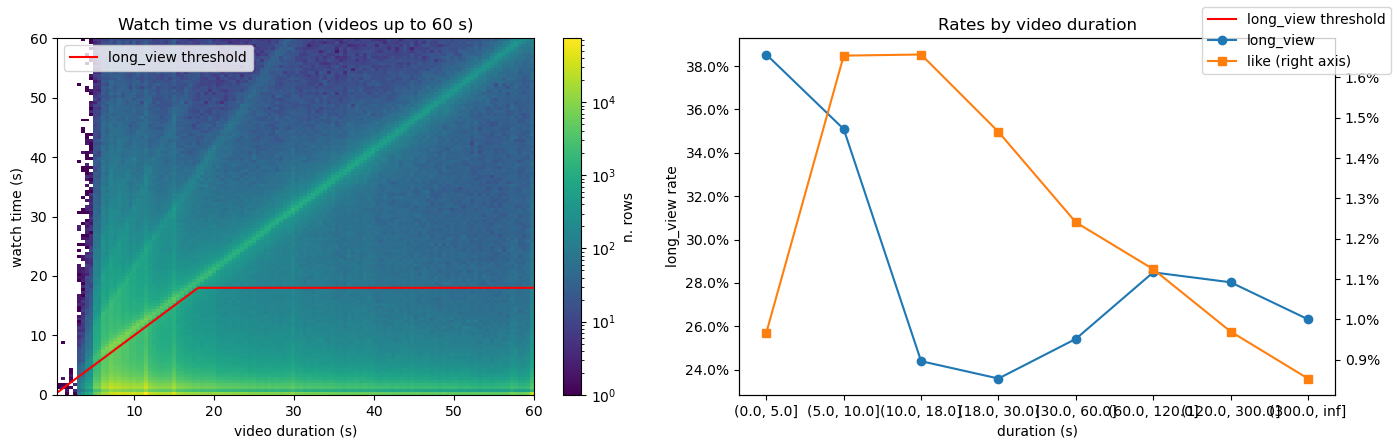

Rows with duration 0: 8.0%  ->  long_view 8.3%, like 4.3%  (rest: long_view 27.8%, like 1.3%)


In [36]:
short = df_log[df_log["duration_ms"].between(1, 60_000) & (df_log["play_time_ms"] <= 60_000)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h = axes[0].hist2d(short["duration_ms"] / 1000, short["play_time_ms"] / 1000,
                   bins=120, norm=LogNorm(), cmap="viridis")
fig.colorbar(h[3], ax=axes[0], label="n. rows")
x = np.linspace(0, 60, 300)
axes[0].plot(x, np.minimum(x, 18), color="red", lw=1.5, label="long_view threshold")
axes[0].set(xlabel="video duration (s)", ylabel="watch time (s)",
            title="Watch time vs duration (videos up to 60 s)")
axes[0].legend(loc="upper left")

nz = df_log[df_log["duration_ms"] > 0]
bins = [0, 5, 10, 18, 30, 60, 120, 300, np.inf]
by_dur = nz.groupby(pd.cut(nz["duration_ms"] / 1000, bins), observed=True)[["long_view", "is_like"]].mean()
labels = by_dur.index.astype(str)
axes[1].plot(labels, by_dur["long_view"], marker="o", label="long_view")
axes[1].set(xlabel="duration (s)", ylabel="long_view rate", title="Rates by video duration")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
ax_like = axes[1].twinx()
ax_like.plot(labels, by_dur["is_like"], marker="s", color="tab:orange", label="like (right axis)")
ax_like.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
fig.legend(loc="upper right")
plt.tight_layout()
plt.show()

zero = df_log["duration_ms"] == 0
print(f"Rows with duration 0: {zero.mean():.1%}  ->  long_view {df_log.loc[zero, 'long_view'].mean():.1%}, "
      f"like {df_log.loc[zero, 'is_like'].mean():.1%}  (rest: long_view {nz['long_view'].mean():.1%}, like {nz['is_like'].mean():.1%})")
del short, nz

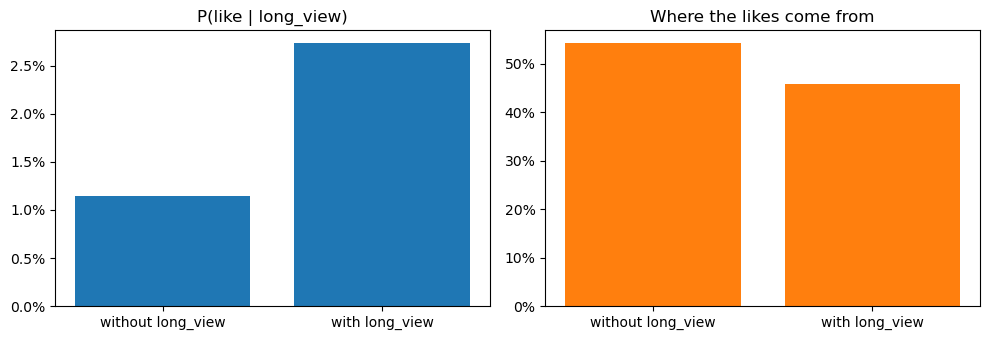

is_like,0,1
long_view,,
0,8544560,99024
1,2985643,83818


In [37]:
ct = pd.crosstab(df_log["long_view"], df_log["is_like"])
p_like = ct[1] / ct.sum(axis=1)
like_origin = ct[1] / ct[1].sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(["without long_view", "with long_view"], p_like.values)
axes[0].set_title("P(like | long_view)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[1].bar(["without long_view", "with long_view"], like_origin.values, color="tab:orange")
axes[1].set_title("Where the likes come from")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()
display(ct)

In [38]:
scope = df_log[(df_log["tab"] == 1) & (df_log["duration_ms"] > 0)]
ct_scope = pd.crosstab(scope["long_view"], scope["is_like"])

print(f"Likes without a long view (tab 1, duration > 0): {ct_scope.loc[0, 1] / ct_scope[1].sum():.1%}")
print(f"P(like | no long_view) = {ct_scope.loc[0, 1] / ct_scope.loc[0].sum():.2%}   "
      f"P(like | long_view) = {ct_scope.loc[1, 1] / ct_scope.loc[1].sum():.2%}")

Likes without a long view (tab 1, duration > 0): 46.0%
P(like | no long_view) = 1.10%   P(like | long_view) = 2.59%


In [39]:
signals = ["long_view", "is_like", "is_follow", "is_comment", "is_forward", "is_hate"]
rate = feed[signals].mean()

sig = pd.DataFrame({
    "positives": feed[signals].sum(),
    "rate": rate,
    "users_with_at_least_one": feed.groupby("user_id")[signals].max().sum(),
})
# Rare binary flags have small correlations almost by construction: the lift is easier to read.
# lift = P(target | signal) / P(target)
for target in ["is_like", "long_view"]:
    sig[f"P({target} | signal)"] = [feed.loc[feed[s] == 1, target].mean() for s in signals]
    sig[f"lift on {target}"] = sig[f"P({target} | signal)"] / rate[target]

display(sig.style.format({"positives": "{:,}", "users_with_at_least_one": "{:,}", "rate": "{:.2%}",
                          "P(is_like | signal)": "{:.1%}", "P(long_view | signal)": "{:.1%}",
                          "lift on is_like": "{:.1f}", "lift on long_view": "{:.1f}"}))
display(feed[signals].corr().round(3))

,positives,rate,users_with_at_least_one,P(is_like | signal),lift on is_like,P(long_view | signal),lift on long_view
long_view,"2,444,305",31.67%,991,2.8%,1.4,100.0%,3.2
is_like,"148,749",1.93%,945,100.0%,51.9,45.8%,1.4
is_follow,"9,226",0.12%,766,46.7%,24.2,66.4%,2.1
is_comment,"24,614",0.32%,678,23.4%,12.1,84.8%,2.7
is_forward,"7,602",0.10%,662,11.2%,5.8,69.9%,2.2
is_hate,"2,515",0.03%,218,0.8%,0.4,25.8%,0.8


,long_view,is_like,is_follow,is_comment,is_forward,is_hate
long_view,1.00,0.04,0.03,0.07,0.03,-0.00
is_like,0.04,1.00,0.11,0.09,0.02,-0.00
is_follow,0.03,0.11,1.00,0.03,0.01,-0.00
is_comment,0.07,0.09,0.03,1.00,0.01,0.00
is_forward,0.03,0.02,0.01,0.01,1.00,0.01
is_hate,-0.00,-0.00,-0.00,0.00,0.01,1.00


**Other feedback signals (tab 1).** Follow, comment, forward and hate are rare: 9,226 follows, 24,614 comments, 7,602 forwards and 2,515 hates, against 148,749 likes and 2.4 M long views. All their pairwise correlations are below 0.12, but for rare binary flags a small correlation is expected by construction, so the lift is more informative: when users follow the author they also like the video in 46.7% of the cases, 24 times the base rate (1.93%), and a comment comes with a like 12 times more often than average. These signals point in the same direction as the like (explicit engagement) but are too rare to be objectives on their own.

`is_hate` is not the opposite of a long view: its correlation with `long_view` is −0.002 and 26% of the hated videos are still watched at length. With 2,515 cases from 218 users it is too sparse to be used as a negative signal.

→ We keep `long_view` and `is_like` as the two objectives. Follows and comments can still enter as user-history features (e.g. "has already followed this author").

#### Users

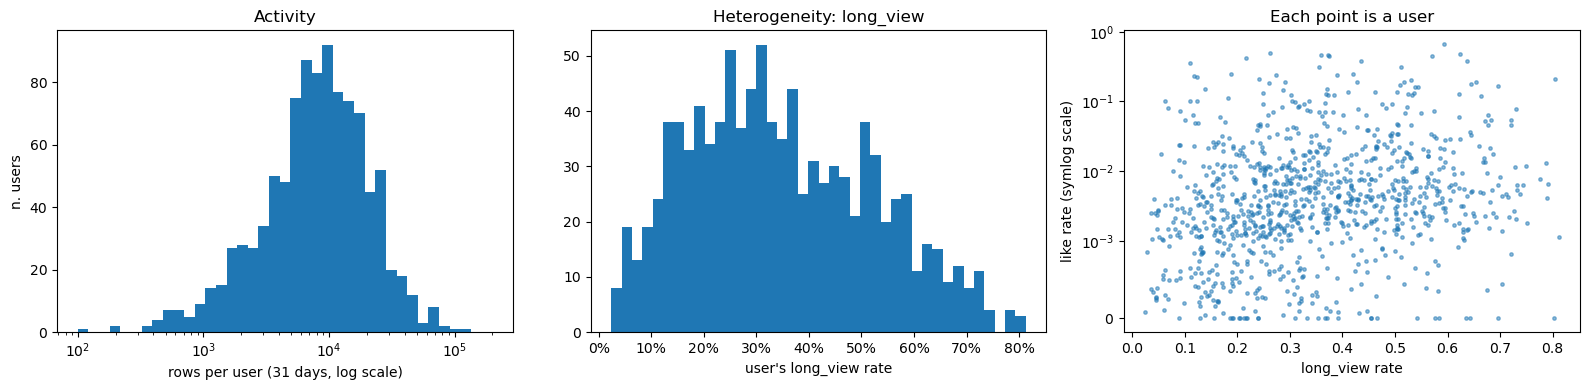

,rows,long_view,like
count,"1,000.00","1,000.00","1,000.00"
mean,"11,713.05",0.35,0.02
std,"11,935.07",0.17,0.06
min,116.00,0.02,0.00
5%,"1,228.80",0.09,0.00
50%,"8,327.50",0.33,0.00
95%,"33,606.00",0.66,0.10
max,"127,557.00",0.81,0.67


Correlation between the two rates (per user): 0.10


In [40]:
per_user = df_log.groupby("user_id").agg(rows=("video_id", "size"),
                                         long_view=("long_view", "mean"),
                                         like=("is_like", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(per_user["rows"], bins=np.logspace(2, 5.3, 40))
axes[0].set(xscale="log", xlabel="rows per user (31 days, log scale)", ylabel="n. users", title="Activity")
axes[1].hist(per_user["long_view"], bins=40)
axes[1].set(xlabel="user's long_view rate", title="Heterogeneity: long_view")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[2].scatter(per_user["long_view"], per_user["like"], s=6, alpha=0.5)
axes[2].set_yscale("symlog", linthresh=1e-3)
axes[2].set(xlabel="long_view rate", ylabel="like rate (symlog scale)", title="Each point is a user")
plt.tight_layout()
plt.show()

display(per_user.describe(percentiles=[0.05, 0.5, 0.95]))
print(f"Correlation between the two rates (per user): {per_user['long_view'].corr(per_user['like']):.2f}")

Tab-1 users: 962 in the train window, 991 in the test window; 29 test users have no tab-1 history
Whole log:   983 users in the train window, 1000 in the test window
Users with >= 200 tab-1 rows in both windows: 901


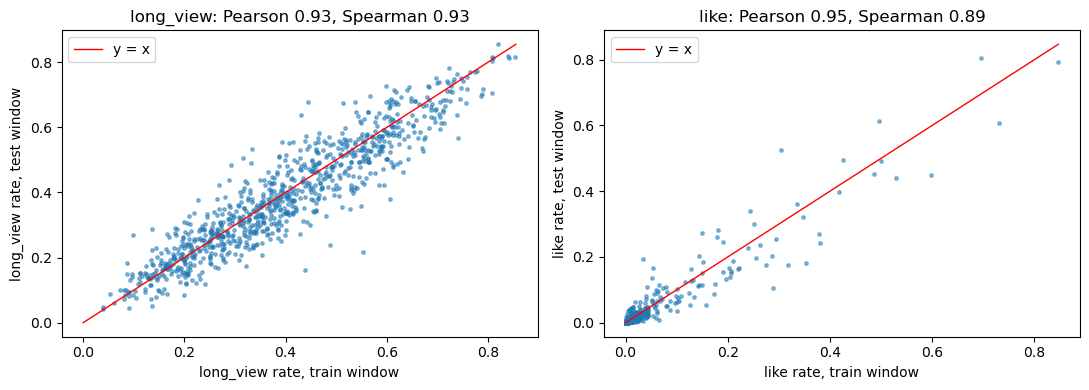

In [41]:
window = np.where(feed["date"] <= 20220421, "train", "test")

users_train = set(feed.loc[window == "train", "user_id"])
users_test = set(feed.loc[window == "test", "user_id"])
print(f"Tab-1 users: {len(users_train)} in the train window, {len(users_test)} in the test window; "
      f"{len(users_test - users_train)} test users have no tab-1 history")
print(f"Whole log:   {df_log.loc[df_log['date'] <= 20220421, 'user_id'].nunique()} users in the train window, "
      f"{df_log.loc[df_log['date'] > 20220421, 'user_id'].nunique()} in the test window")

by_window = (feed.groupby(["user_id", window])
                 .agg(rows=("long_view", "size"), long_view=("long_view", "mean"), like=("is_like", "mean"))
                 .unstack())
enough = (by_window["rows"] >= 200).all(axis=1)    # rates estimated on at least 200 rows per window
stable = by_window[enough]
print(f"Users with >= 200 tab-1 rows in both windows: {enough.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target in zip(axes, ["long_view", "like"]):
    x, y = stable[(target, "train")], stable[(target, "test")]
    ax.scatter(x, y, s=6, alpha=0.5)
    lim = max(x.max(), y.max())
    ax.plot([0, lim], [0, lim], color="red", lw=1, label="y = x")
    # Spearman = Pearson on ranks (method="spearman" would need scipy)
    ax.set(xlabel=f"{target} rate, train window", ylabel=f"{target} rate, test window",
           title=f"{target}: Pearson {x.corr(y):.2f}, Spearman {x.rank().corr(y.rank()):.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

**Do users behave the same way in the two windows?** For the 901 users with at least 200 tab-1 rows in both windows, the long-view rate of the train window predicts the one of the test window very well (Pearson and Spearman 0.93). The same holds for the like rate (Pearson 0.95), but its Pearson is driven by a few users with very high like rates while most users sit close to zero: on ranks the correlation is 0.89.

→ The differences between users are stable, not noise: the user's past rates (group 2) will carry a lot of signal. The flip side is that the user's historical rate alone is already a strong baseline, and groups 3 and 4 will have to show what they add beyond it.

→ Cold start: 29 of the 991 tab-1 users of the test window have no tab-1 history in the train window, and 17 users have no history at all (983 users in the train window, 1,000 in the test window). Their user features will be missing and must be handled explicitly (e.g. with the global average).

#### Videos and popularity

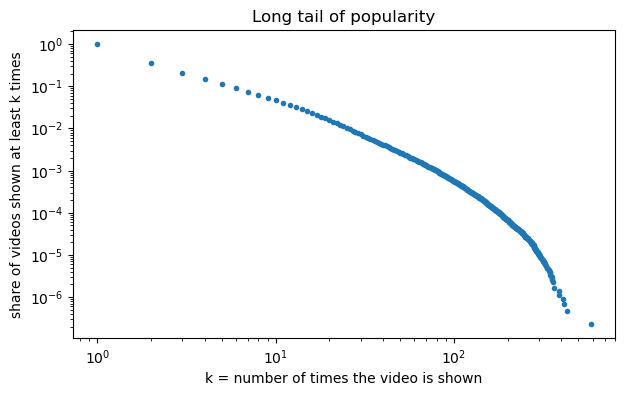

Distinct videos: 4,369,953
Shown once: 65.0%   fewer than 5 times: 88.8%
The top 1% most-shown videos cover 17.4% of the rows


In [42]:
per_video = df_log.groupby("video_id").size()
freq = per_video.value_counts().sort_index()
ccdf = freq[::-1].cumsum()[::-1] / len(per_video)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ccdf.index, ccdf.values, marker=".", ls="none")
ax.set(xlabel="k = number of times the video is shown", ylabel="share of videos shown at least k times",
       title="Long tail of popularity")
plt.show()

print(f"Distinct videos: {len(per_video):,}")
print(f"Shown once: {(per_video == 1).mean():.1%}   fewer than 5 times: {(per_video < 5).mean():.1%}")
top = per_video.nlargest(len(per_video) // 100).sum() / per_video.sum()
print(f"The top 1% most-shown videos cover {top:.1%} of the rows")

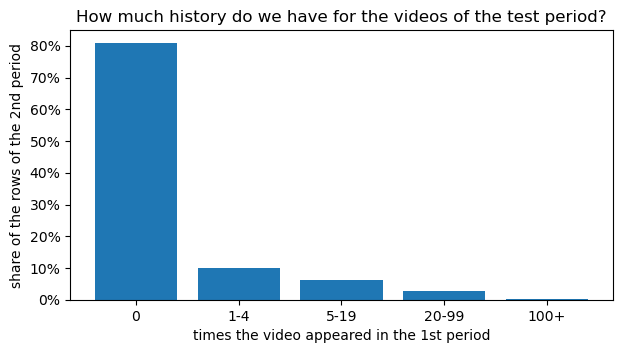

video_id
0       0.81
1-4     0.10
5-19    0.06
20-99   0.03
100+    0.00
Name: proportion, dtype: float64

In [43]:
period1 = df_log["date"] <= 20220421
cnt1 = df_log.loc[period1].groupby("video_id").size()
hist_n = df_log.loc[~period1, "video_id"].map(cnt1).fillna(0)

bins = [-1, 0, 4, 19, 99, np.inf]
lbl = ["0", "1-4", "5-19", "20-99", "100+"]
share = pd.cut(hist_n, bins, labels=lbl).value_counts(normalize=True).reindex(lbl)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(share.index, share.values)
ax.set(xlabel="times the video appeared in the 1st period", ylabel="share of the rows of the 2nd period",
       title="How much history do we have for the videos of the test period?")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(share)

#### Repeated videos and position in the session
Two context variables that are known when a block is requested: whether the user has already seen the video, and how far into the session the user is (tab 1 only).

In [44]:
# n-th time this user is shown this video (rank on time; ties broken by row order)
showing = feed.groupby(["user_id", "video_id"])["time_ms"].rank(method="first")
showing_bin = pd.cut(showing, [0, 1, 2, np.inf], labels=["1st", "2nd", "3rd+"])

repeats = feed.groupby(showing_bin, observed=True).agg(rows=("user_id", "size"),
                                                       long_view=("long_view", "mean"),
                                                       like=("is_like", "mean"))
repeats.insert(1, "share_of_rows", repeats["rows"] / len(feed))
display(repeats.style.format({"rows": "{:,}", "share_of_rows": "{:.2%}", "long_view": "{:.1%}", "like": "{:.2%}"}))

,rows,share_of_rows,long_view,like
time_ms,,,,
1st,"7,652,633",99.16%,31.8%,1.93%
2nd,"61,112",0.79%,16.4%,1.08%
3rd+,"3,856",0.05%,9.6%,0.80%


**Already-seen videos.** 0.84% of the tab-1 rows show a video that the same user had already been shown (61,112 second showings and 3,856 third or later). The long-view rate halves at the second showing (16.4% against 31.8%) and drops again at the third (9.6%); the like rate follows (1.08% against 1.93%).

→ Instead of removing these rows (the recommender really shows them, and removing them would change the feed we evaluate), the number of previous showings of the video to the same user is a legitimate feature for group 4, since it is computed only from the past.

Sessions: 134,411   blocks per session: median 4, 90th pct 26


,rows,long_view,like,long_view_vs_user,like_vs_user
position_bin,,,,,
1,"607,085",45.2%,3.16%,+7.7%,+0.80%
2-5,"1,709,376",39.1%,2.55%,+3.0%,+0.31%
6-10,"1,359,695",34.9%,2.10%,+0.7%,+0.02%
11-20,"1,534,150",30.8%,1.76%,-1.0%,-0.17%
21-50,"1,617,332",25.1%,1.41%,-3.0%,-0.32%
51+,"889,963",16.7%,0.88%,-4.9%,-0.29%


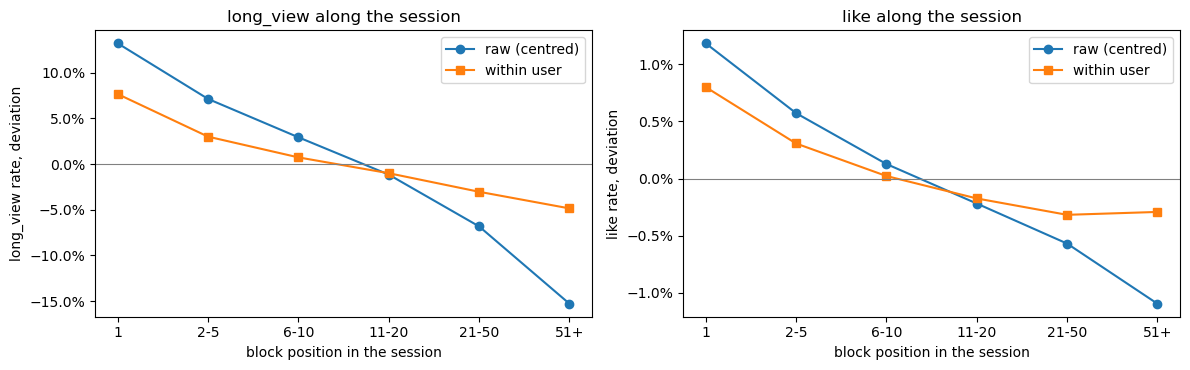

In [45]:
# A session is a sequence of tab-1 blocks of the same user with gaps shorter than 30 minutes
SESSION_GAP_MS = 30 * 60 * 1000
blk = feed[["user_id", "time_ms"]].drop_duplicates().sort_values(["user_id", "time_ms"])
gap = blk.groupby("user_id")["time_ms"].diff()
blk["session"] = (gap.isna() | (gap > SESSION_GAP_MS)).groupby(blk["user_id"]).cumsum()
blk["position"] = blk.groupby(["user_id", "session"]).cumcount() + 1     # block index in the session

sessions = blk.groupby(["user_id", "session"]).size()
print(f"Sessions: {len(sessions):,}   blocks per session: median {sessions.median():.0f}, 90th pct {sessions.quantile(0.9):.0f}")

pos = feed[["user_id", "time_ms", "long_view", "is_like"]].merge(blk, on=["user_id", "time_ms"])
labels = ["1", "2-5", "6-10", "11-20", "21-50", "51+"]
pos["position_bin"] = pd.cut(pos["position"], [0, 1, 5, 10, 20, 50, np.inf], labels=labels)

# Raw rates mix users: long sessions belong mostly to very active users with lower rates.
# Subtracting each user's own mean compares every user with themself.
for c in ["long_view", "is_like"]:
    pos[f"{c}_vs_user"] = pos[c] - pos.groupby("user_id")[c].transform("mean")
by_pos = pos.groupby("position_bin", observed=True).agg(
    rows=("user_id", "size"), long_view=("long_view", "mean"), like=("is_like", "mean"),
    long_view_vs_user=("long_view_vs_user", "mean"), like_vs_user=("is_like_vs_user", "mean"))
display(by_pos.style.format({"rows": "{:,}", "long_view": "{:.1%}", "like": "{:.2%}",
                             "long_view_vs_user": "{:+.1%}", "like_vs_user": "{:+.2%}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (raw, within, name) in zip(axes, [("long_view", "long_view_vs_user", "long_view"),
                                         ("like", "like_vs_user", "like")]):
    ax.plot(labels, by_pos[raw] - by_pos[raw].mean(), marker="o", label="raw (centred)")
    ax.plot(labels, by_pos[within], marker="s", label="within user")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(xlabel="block position in the session", ylabel=f"{name} rate, deviation",
           title=f"{name} along the session")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.legend()
plt.tight_layout()
plt.show()
del pos

**Attention along the session.** A session is a sequence of tab-1 blocks of the same user with gaps shorter than 30 minutes (a conventional threshold): 134,411 sessions, median 4 blocks, 10% longer than 26 blocks. The raw long-view rate falls from 45% in the first block to 17% after the 50th, but long sessions belong mostly to very active users, who have lower rates in general. Comparing each user with themself (rate minus the user's own mean) the decline remains, about half as large: from +7.7 to −4.9 percentage points for the long view, from +0.8 to −0.3 points for the like.

→ The position in the session is known when the block is requested, so it is a legitimate context feature. About half of the raw decline is a composition effect: without the within-user comparison we would have overestimated it.

#### Time

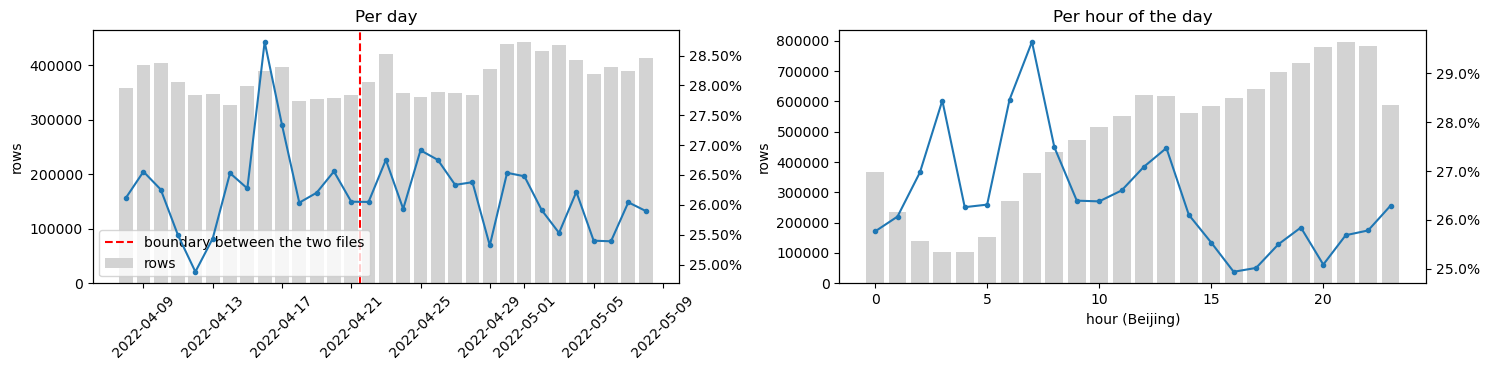

In [46]:
daily = df_log.groupby("date").agg(rows=("user_id", "size"),
                                   long_view=("long_view", "mean"),
                                   like=("is_like", "mean"))
daily.index = pd.to_datetime(daily.index.astype(str), format="%Y%m%d")
hourly = df_log.groupby(df_log["hourmin"] // 100).agg(rows=("user_id", "size"),
                                                      long_view=("long_view", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].bar(daily.index, daily["rows"], color="lightgray", label="rows")
axes[0].axvline(pd.Timestamp("2022-04-21 12:00"), color="red", ls="--", label="boundary between the two files")
axes[0].set(ylabel="rows", title="Per day")
ax_r = axes[0].twinx()
ax_r.plot(daily.index, daily["long_view"], color="tab:blue", marker="o", ms=3, label="long_view")
ax_r.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc="lower left")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(hourly.index, hourly["rows"], color="lightgray")
axes[1].set(xlabel="hour (Beijing)", ylabel="rows", title="Per hour of the day")
ax_r2 = axes[1].twinx()
ax_r2.plot(hourly.index, hourly["long_view"], color="tab:blue", marker="o", ms=3)
ax_r2.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

### What we learned from the standard logs
- **Two interfaces, two problems.** Tabs 1/2/4 behave like the single-column feed (blocks of ~6 videos, almost all of them played); tabs 0/3/8/11/12 like the grid (>85% never opened; blocks of ~11 videos in tabs 0 and 3). In the grid `long_view=0` mostly means "never clicked". Tab 4 is the feed opened from a grid thumbnail (97% of its entries come from a grid tab, within seconds). **Scope: tab 1**, the main feed; tab 4 is kept as a possible comparison.
- **`time_ms` is the instant of the request**, shared by 98.7% of the rows: sequential features must be built only on previous blocks.
- **`long_view` is a deterministic rule on `play_time_ms` and `duration_ms`**: `play_time_ms` cannot be a feature; the effect of duration is partly mechanical (18 s threshold).
- **Like and long_view diverge**: even excluding zero-duration videos and staying in tab 1, 46% of the likes come without a long view → the trade-off of the project work is real.
- **Very heterogeneous users** (long_view from 2% to 81%; correlation between the two rates 0.10) → room for personalization; metrics to be computed per user.
- **Stable users**: in tab 1 the user's rates in the train window predict those in the test window (long view 0.93, like 0.89 on ranks) → group 2 will be strong, and the user's historical rate is the baseline to beat. 29 test users have no tab-1 history.
- **Other signals**: follow, comment, forward and hate are rare (2.5k–25k cases) and go with the like (follow → like 24× the base rate); `is_hate` is too sparse and unrelated to the long view → the objectives stay `long_view` and `is_like`.
- **Context matters**: a video shown again to the same user (0.8% of the rows) has half the long-view rate, and within the same user the long-view rate drops by about 12 points from the first block of a session to the 50th → "previous showings" and "position in the session" are candidate features.
- **Per-video popularity almost absent**: 81% of the rows of the 2nd period are about videos never seen in the 1st → the popularity baseline must be defined at a more aggregated level or on a subset of videos.
- **No temporal drift** in the rates: the train/test split by date makes sense.
- **Open questions** (no rows removed yet): 101,220 duplicate rows (90% in tab 6) and 8% of rows with `duration_ms = 0` (like rate 4.3%, long_view not very meaningful: maybe photo posts, to be checked with `video_features_basic`).

### Random log
In the random-exposure stage, a recommended video could be replaced by a video sampled at random from a pool, independently of the recommender. The abstract uses these impressions as a second test set; here we check how they are structured and how much they can support.

In [47]:
PATH_RAND = DATA_DIR / "log_random_4_22_to_5_08_1k.csv"
df_rand = load_log(PATH_RAND)     # same dtypes as the standard log

print(f"Rows: {len(df_rand):,}   users: {df_rand['user_id'].nunique()}   videos: {df_rand['video_id'].nunique():,}")
print(f"Dates: {df_rand['date'].min()} -> {df_rand['date'].max()}   is_rand values: {sorted(df_rand['is_rand'].unique())}")
print(f"Video ids: {df_rand['video_id'].min()} -> {df_rand['video_id'].max()}")
display(df_rand["tab"].value_counts(normalize=True).rename("share of rows").to_frame().style.format("{:.1%}"))

Rows: 43,028   users: 1000   videos: 7,388
Dates: 20220422 -> 20220508   is_rand values: [np.int8(1)]
Video ids: 0 -> 7387


,share of rows
tab,
1,99.1%
11,0.7%
2,0.2%
14,0.0%


In [48]:
# Is each random video inserted inside a block of the normal feed (same user, same time_ms)?
std_blocks = pd.MultiIndex.from_frame(df_log[["user_id", "time_ms"]].drop_duplicates())
inside = pd.MultiIndex.from_frame(df_rand[["user_id", "time_ms"]]).isin(std_blocks)
print(f"Random rows sharing their time_ms with a standard block: {inside.mean():.1%}")

per_block = df_rand.groupby(["user_id", "time_ms"]).size()
print(f"Random videos per block: {per_block.value_counts(normalize=True).sort_index().head(3).map('{:.1%}'.format).to_dict()}")

per_user = df_rand.groupby("user_id").size()
print(f"Random rows per user: median {per_user.median():.0f}, min {per_user.min()}, max {per_user.max()}")

Random rows sharing their time_ms with a standard block: 96.5%
Random videos per block: {1: '100.0%', 2: '0.0%'}
Random rows per user: median 22, min 10, max 650


**Structure of the random log.** 43,028 random impressions, 1,000 users, 7,388 videos (ids 0–7387, the candidate pool), all in the test window (22/4–8/5) and 99.1% in tab 1. Each random video arrives alone (one per block) inside a block of the normal feed: 96.5% share their `time_ms` with a standard block. Users received a median of 22 random videos over 17 days (from 10 to 650).

→ The random log is not a feed: there are no blocks of random candidates to rank, only a small, scattered set of impressions per user. For consistency with the scope we use its tab-1 rows (42,636).

,standard feed (tab 1),random (tab 1),random / standard
rows,"4,431,299","42,636",0.01
long_view,31.47%,8.48%,0.27
like,2.00%,0.56%,0.28
never_opened,1.14%,0.24%,0.21
median_play_s,4.9,2.1,0.43
median_duration_s,25.5,77.4,3.03
duration_0,7.42%,3.04%,0.41


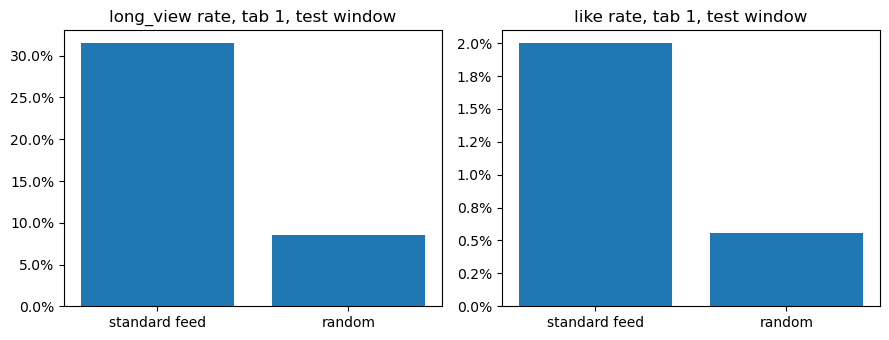

In [49]:
# Same tab (1) and same window (22/4 - 8/5): the only difference is who chose the video
rand1 = df_rand[df_rand["tab"] == 1]
feed_test = feed[feed["date"] > 20220421]

def describe_impressions(d):
    return pd.Series({"rows": len(d),
                      "long_view": d["long_view"].mean(),
                      "like": d["is_like"].mean(),
                      "never_opened": d["play_time_ms"].eq(0).mean(),
                      "median_play_s": d["play_time_ms"].median() / 1000,
                      "median_duration_s": d["duration_ms"].median() / 1000,
                      "duration_0": d["duration_ms"].eq(0).mean()})

comparison = pd.DataFrame({"standard feed (tab 1)": describe_impressions(feed_test),
                           "random (tab 1)": describe_impressions(rand1)})
comparison["random / standard"] = comparison["random (tab 1)"] / comparison["standard feed (tab 1)"]
rates = ["long_view", "like", "never_opened", "duration_0"]
seconds = ["median_play_s", "median_duration_s"]
both = ["standard feed (tab 1)", "random (tab 1)"]
display(comparison.style
        .format("{:,.0f}", subset=pd.IndexSlice[["rows"], both])
        .format("{:.2%}", subset=pd.IndexSlice[rates, both])
        .format("{:.1f}", subset=pd.IndexSlice[seconds, both])
        .format("{:.2f}", subset=pd.IndexSlice[:, ["random / standard"]]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, col in zip(axes, ["long_view", "like"]):
    ax.bar(["standard feed", "random"], comparison.loc[col, ["standard feed (tab 1)", "random (tab 1)"]])
    ax.set_title(f"{col} rate, tab 1, test window")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
plt.tight_layout()
plt.show()

**Random against the normal feed** (tab 1, test window). The long-view rate is 8.5% against 31.5% (×0.27) and the like rate 0.56% against 2.00% (×0.28). This gap is the exposure bias: what users do with the videos the recommender chose for them is very different from what they do with any video. The comparison mixes two effects, the recommender's choice and the composition of the random pool, whose videos are also much longer (median duration 77 s against 26 s) and less often without a duration (3% against 7%). Duration alone is unlikely to explain the gap: in the standard log the long-view rate stays between 24% and 35% for every duration bin above 10 s.

→ A model trained on the normal feed learns from a highly selected sample; the random log tests whether it still ranks well when exposure did not depend on the recommender.

In [50]:
# How many positives does the random log offer as a test set, and how many users carry them?
per_user_r = rand1.groupby("user_id").agg(rows=("long_view", "size"),
                                          long_view=("long_view", "sum"),
                                          like=("is_like", "sum"))
for col in ["long_view", "like"]:
    print(f"{col:9s}: {per_user_r[col].sum():>5,} positives, from {(per_user_r[col] > 0).sum()} users "
          f"(of {len(per_user_r)})")

# Bootstrap over users: the user is the unit that is sampled, rows of the same user are not independent
rng = np.random.default_rng(0)
B = 2000
idx = rng.integers(0, len(per_user_r), size=(B, len(per_user_r)))
rows_b = per_user_r["rows"].to_numpy()[idx].sum(axis=1)
for col in ["long_view", "like"]:
    rate_b = per_user_r[col].to_numpy()[idx].sum(axis=1) / rows_b
    lo, hi = np.percentile(rate_b, [2.5, 97.5])
    point = per_user_r[col].sum() / per_user_r["rows"].sum()
    print(f"{col:9s} rate {point:.2%}  95% CI [{lo:.2%}, {hi:.2%}]  (relative half-width {(hi - lo) / 2 / point:.0%})")

long_view: 3,614 positives, from 693 users (of 988)
like     :   239 positives, from 86 users (of 988)
long_view rate 8.48%  95% CI [7.82%, 9.23%]  (relative half-width 8%)
like      rate 0.56%  95% CI [0.30%, 0.96%]  (relative half-width 59%)


**How much can the random log support as a test set?** For the long view there are 3,614 positives from 693 users, and the 95% bootstrap interval of the rate is narrow (±8% relative). For the like there are only 239 positives from 86 users: the interval is [0.30%, 0.96%] (±59% relative).

→ Metrics on the long view in the random log are usable; metrics on the like will be very noisy and must be reported with confidence intervals (bootstrap over users). Per-user top-10 metrics make little sense there (a median user has 22 random rows over 17 days, and 902 users have no random like): on the random log we will use pointwise metrics such as AUC or log-loss.

Random videos seen at least once in the train window: 70.0%; median impressions: 2


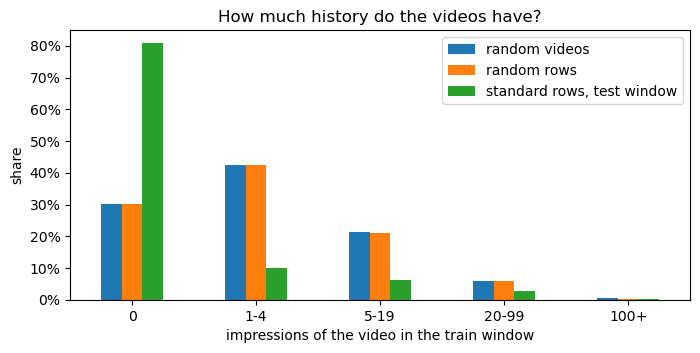

,random videos,random rows,"standard rows, test window"
0,30.0%,30.1%,80.9%
1-4,42.3%,42.5%,9.9%
5-19,21.2%,21.2%,6.3%
20-99,6.1%,5.9%,2.7%
100+,0.4%,0.3%,0.2%


In [51]:
# Do the random videos have a history in the train window (all tabs)? Popularity can only be estimated from there
train_counts = df_log.loc[df_log["date"] <= 20220421].groupby("video_id").size()

bins = [-1, 0, 4, 19, 99, np.inf]
lbl = ["0", "1-4", "5-19", "20-99", "100+"]
hist_videos = pd.Series(df_rand["video_id"].unique()).map(train_counts).fillna(0)
hist_rows = df_rand["video_id"].map(train_counts).fillna(0)
history = pd.DataFrame({
    "random videos": pd.cut(hist_videos, bins, labels=lbl).value_counts(normalize=True).reindex(lbl),
    "random rows": pd.cut(hist_rows, bins, labels=lbl).value_counts(normalize=True).reindex(lbl),
    "standard rows, test window": pd.cut(df_log.loc[df_log["date"] > 20220421, "video_id"].map(train_counts).fillna(0),
                                         bins, labels=lbl).value_counts(normalize=True).reindex(lbl),
})
print(f"Random videos seen at least once in the train window: {(hist_videos > 0).mean():.1%}; "
      f"median impressions: {hist_videos.median():.0f}")

ax = history.plot.bar(figsize=(8, 3.5), rot=0)
ax.set(xlabel="impressions of the video in the train window", ylabel="share",
       title="How much history do the videos have?")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(history.style.format("{:.1%}"))

**Do the random videos have a history?** 70% of the random videos already appear in the train window, against 19% of the rows of the standard test window, but with a median of only 2 impressions: just 6.5% of them have at least 20 (6.2% of the random rows).

→ The random pool is better covered than the normal feed, but our 1,000 users are too few to estimate per-video popularity in either case: the popularity baseline (group 1) must be defined at a more aggregated level (author, tag) or with a rate shrunk towards the global mean when a video has few impressions.

### What we learned from the random log
- **Structure**: one random video per block, inserted in the normal feed; 43,028 rows, 99% in tab 1, test window only, a median of 22 per user.
- **Exposure bias**: in tab 1 the long-view rate is 8.5% against 31.5% in the normal feed and the like rate 0.56% against 2.0%: less than a third. Part of the gap may come from the composition of the random pool (videos three times longer).
- **Test-set size**: adequate for the long view (3,614 positives from 693 users), weak for the like (239 positives from 86 users) → confidence intervals, pointwise metrics, no per-user top-10 on the random log.
- **Popularity**: the random videos have more history than the normal feed (70% already seen in the train window, against 19%) but still few impressions (median 2) → popularity at author/tag level or shrunk towards the global mean.
- **Open questions** for `video_features_basic`: why the random videos are so much longer, the zero-duration rows, the duplicates in tab 6.